In [1]:
%pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [2]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    roc_auc_score,
    classification_report,
    ConfusionMatrixDisplay
)

print("All libraries imported successfully!")


All libraries imported successfully!


In [3]:

import pandas as pd

df = pd.read_csv("yeast.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())


Dataset loaded successfully!
Dataset shape: (1484, 9)


,mcg,gvh,alm,mit,erl,pox,vac,nuc,name
0,0.58,0.61,0.47,0.13,0.5,0.0,0.48,0.22,MIT
1,0.43,0.67,0.48,0.27,0.5,0.0,0.53,0.22,MIT
2,0.64,0.62,0.49,0.15,0.5,0.0,0.53,0.22,MIT
3,0.58,0.44,0.57,0.13,0.5,0.0,0.54,0.22,NUC
4,0.42,0.44,0.48,0.54,0.5,0.0,0.48,0.22,MIT


In [4]:

# Display all column names
print("Column names:")
print(df.columns.tolist())

# Display data types and non-null counts
print("\nDataset information:")
df.info()

# Count missing values in each column
print("\nMissing values per column:")
print(df.isnull().sum())


Column names:
['mcg', 'gvh', 'alm', 'mit', 'erl', 'pox', 'vac', 'nuc', 'name']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 1484 entries, 0 to 1483
Data columns (total 9 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   mcg     1484 non-null   float64
 1   gvh     1484 non-null   float64
 2   alm     1484 non-null   float64
 3   mit     1484 non-null   float64
 4   erl     1484 non-null   float64
 5   pox     1484 non-null   float64
 6   vac     1484 non-null   float64
 7   nuc     1484 non-null   float64
 8   name    1484 non-null   str    
dtypes: float64(8), str(1)
memory usage: 104.5 KB

Missing values per column:
mcg     0
gvh     0
alm     0
mit     0
erl     0
pox     0
vac     0
nuc     0
name    0
dtype: int64


Samples per localization class:
name
CYT    463
NUC    429
MIT    244
ME3    163
ME2     51
ME1     44
EXC     35
VAC     30
POX     20
ERL      5
Name: count, dtype: int64

Number of unique classes: 10


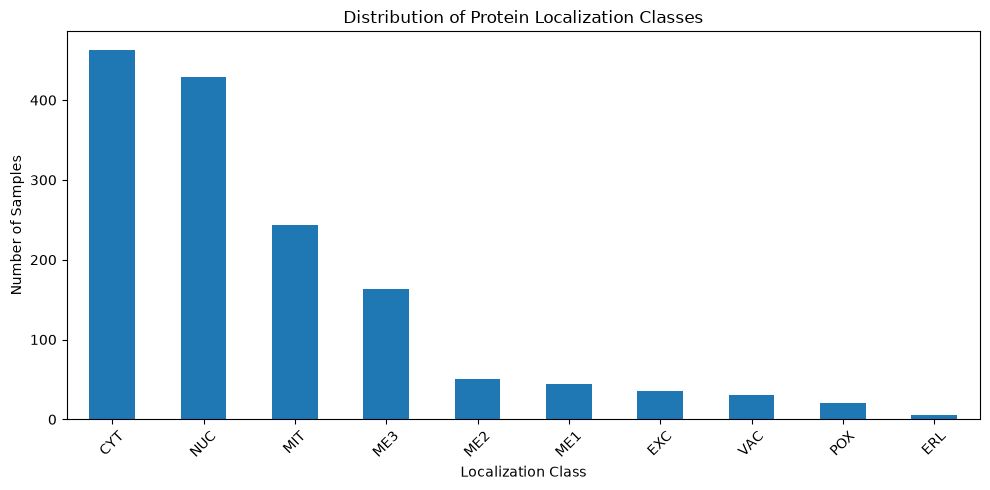

In [5]:
# Count the samples belonging to each localization class
class_counts = df["name"].value_counts()

print("Samples per localization class:")
print(class_counts)

print("\nNumber of unique classes:", df["name"].nunique())

# Visualize the class distribution
class_counts.plot(kind="bar", figsize=(10, 5))

plt.title("Distribution of Protein Localization Classes")
plt.xlabel("Localization Class")
plt.ylabel("Number of Samples")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [6]:

# Input features: all columns except the target
X = df.drop(columns=["name"])

# Target labels: the column we want to predict
y = df["name"]

print("Shape of X:", X.shape)
print("Shape of y:", y.shape)

print("\nFirst 5 feature rows:")
display(X.head())

print("\nFirst 5 target labels:")
display(y.head())


Shape of X: (1484, 8)
Shape of y: (1484,)

First 5 feature rows:


,mcg,gvh,alm,mit,erl,pox,vac,nuc
0,0.58,0.61,0.47,0.13,0.5,0.0,0.48,0.22
1,0.43,0.67,0.48,0.27,0.5,0.0,0.53,0.22
2,0.64,0.62,0.49,0.15,0.5,0.0,0.53,0.22
3,0.58,0.44,0.57,0.13,0.5,0.0,0.54,0.22
4,0.42,0.44,0.48,0.54,0.5,0.0,0.48,0.22



First 5 target labels:


0    MIT
1    MIT
2    MIT
3    NUC
4    MIT
Name: name, dtype: str

In [7]:

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training labels:", y_train.shape)
print("Testing labels:", y_test.shape)


Training features: (1187, 8)
Testing features: (297, 8)
Training labels: (1187,)
Testing labels: (297,)


In [8]:

# Create a Decision Tree classifier
model = DecisionTreeClassifier(
    criterion="gini",
    random_state=42
)

# Train the model using the training data
model.fit(X_train, y_train)

print("Decision Tree trained successfully!")
print("Tree depth:", model.get_depth())
print("Number of leaves:", model.get_n_leaves())


Decision Tree trained successfully!
Tree depth: 24
Number of leaves: 420


In [9]:

# Predictions on the training set
y_train_pred = model.predict(X_train)

# Predictions on the unseen test set
y_test_pred = model.predict(X_test)

print("First 10 actual labels:")
print(y_test.iloc[:10].tolist())

print("\nFirst 10 predicted labels:")
print(y_test_pred[:10].tolist())

print("\nNumber of test predictions:", len(y_test_pred))


First 10 actual labels:
['CYT', 'ME3', 'NUC', 'NUC', 'NUC', 'ME1', 'CYT', 'CYT', 'CYT', 'NUC']

First 10 predicted labels:
['NUC', 'ME3', 'NUC', 'NUC', 'NUC', 'ME1', 'MIT', 'CYT', 'NUC', 'VAC']

Number of test predictions: 297


In [10]:

# Calculate accuracy on training data
train_accuracy = accuracy_score(y_train, y_train_pred)

# Calculate accuracy on test data
test_accuracy = accuracy_score(y_test, y_test_pred)

print(f"Training accuracy: {train_accuracy:.4f}")
print(f"Test accuracy:     {test_accuracy:.4f}")
print(f"Accuracy gap:      {train_accuracy - test_accuracy:.4f}")


Training accuracy: 1.0000
Test accuracy:     0.5118
Accuracy gap:      0.4882


In [11]:

from sklearn.model_selection import GridSearchCV, StratifiedKFold

# Define the cross-validation strategy
cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

# Define the combinations of hyperparameters to try
param_grid = {
    "max_depth": [5, 10, 15, None],
    "min_samples_split": [2, 10, 20],
    "min_samples_leaf": [2, 5, 10]
}

# Set up grid search
grid_search = GridSearchCV(
    estimator=DecisionTreeClassifier(
        criterion="gini",
        random_state=42
    ),
    param_grid=param_grid,
    scoring="f1_macro",
    cv=cv,
    n_jobs=-1,
    refit=True
)

# Search using only the training data
grid_search.fit(X_train, y_train)

print("Best hyperparameters:")
print(grid_search.best_params_)

print("\nBest cross-validation macro F1:")
print(round(grid_search.best_score_, 4))

print("\nNumber of parameter combinations:", len(grid_search.cv_results_["params"]))


Best hyperparameters:
{'max_depth': 10, 'min_samples_leaf': 2, 'min_samples_split': 10}

Best cross-validation macro F1:
0.4329

Number of parameter combinations: 36


In [12]:

# Retrieve the best model selected by grid search
best_model = grid_search.best_estimator_

# Predict on the held-out test set
y_test_tuned_pred = best_model.predict(X_test)

# Calculate evaluation metrics
test_accuracy_tuned = accuracy_score(y_test, y_test_tuned_pred)

test_macro_f1 = f1_score(
    y_test, y_test_tuned_pred,
    average="macro", zero_division=0
)

test_weighted_f1 = f1_score(
    y_test, y_test_tuned_pred,
    average="weighted", zero_division=0
)

test_macro_recall = recall_score(
    y_test, y_test_tuned_pred,
    average="macro", zero_division=0
)

test_mcc = matthews_corrcoef(y_test, y_test_tuned_pred)

print("TUNED DECISION TREE — TEST RESULTS")
print("-" * 40)
print(f"Accuracy:     {test_accuracy_tuned:.4f}")
print(f"Macro F1:     {test_macro_f1:.4f}")
print(f"Weighted F1:  {test_weighted_f1:.4f}")
print(f"Macro Recall: {test_macro_recall:.4f}")
print(f"MCC:          {test_mcc:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_test_tuned_pred,
    zero_division=0
))


TUNED DECISION TREE — TEST RESULTS
----------------------------------------
Accuracy:     0.5387
Macro F1:     0.3914
Weighted F1:  0.5326
Macro Recall: 0.3750
MCC:          0.3961

Classification Report:
              precision    recall  f1-score   support

         CYT       0.51      0.63      0.57        93
         ERL       0.00      0.00      0.00         1
         EXC       0.12      0.14      0.13         7
         ME1       0.67      0.67      0.67         9
         ME2       0.40      0.40      0.40        10
         ME3       0.77      0.62      0.69        32
         MIT       0.55      0.53      0.54        49
         NUC       0.53      0.50      0.51        86
         POX       1.00      0.25      0.40         4
         VAC       0.00      0.00      0.00         6

    accuracy                           0.54       297
   macro avg       0.46      0.37      0.39       297
weighted avg       0.54      0.54      0.53       297



In [13]:

# Predict on the training set using the tuned model
y_train_tuned_pred = best_model.predict(X_train)

# Calculate training accuracy
train_accuracy_tuned = accuracy_score(
    y_train, y_train_tuned_pred
)

# Calculate the training-test accuracy gap
gap_tuned = train_accuracy_tuned - test_accuracy_tuned

print(f"Tuned tree depth: {best_model.get_depth()}")
print(f"Tuned tree leaves: {best_model.get_n_leaves()}")
print(f"Tuned training accuracy: {train_accuracy_tuned:.4f}")
print(f"Tuned test accuracy: {test_accuracy_tuned:.4f}")
print(f"Tuned accuracy gap: {gap_tuned:.4f}")


Tuned tree depth: 10
Tuned tree leaves: 121
Tuned training accuracy: 0.7489
Tuned test accuracy: 0.5387
Tuned accuracy gap: 0.2102


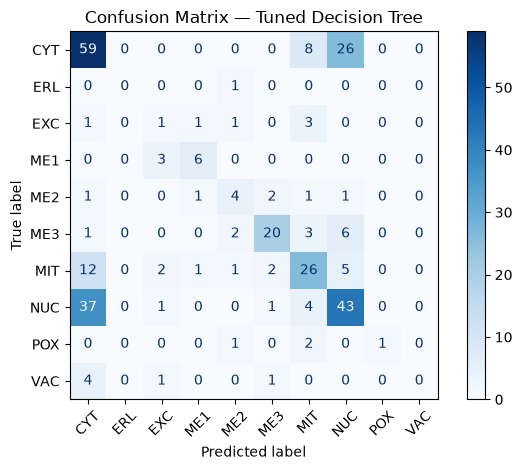

In [14]:

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_test_tuned_pred,
    labels=best_model.classes_,
    xticks_rotation=45,
    cmap="Blues"
)

plt.title("Confusion Matrix — Tuned Decision Tree")
plt.tight_layout()
plt.show()


In [15]:

# Obtain predicted probabilities for each class
y_test_proba = best_model.predict_proba(X_test)

# Calculate one-vs-rest multiclass ROC-AUC
test_auc = roc_auc_score(
    y_test,
    y_test_proba,
    labels=best_model.classes_,
    multi_class="ovr",
    average="macro"
)

print(f"Test macro ROC-AUC: {test_auc:.4f}")


Test macro ROC-AUC: 0.6880


In [16]:

results = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Macro F1",
        "Weighted F1",
        "Macro Recall",
        "Matthews Correlation Coefficient",
        "Macro ROC-AUC"
    ],
    "Test Score": [
        test_accuracy_tuned,
        test_macro_f1,
        test_weighted_f1,
        test_macro_recall,
        test_mcc,
        test_auc
    ]
})

results["Test Score"] = results["Test Score"].round(4)

display(results)

print("\nSelected hyperparameters:")
print(grid_search.best_params_)

print("\nCross-validation macro F1:")
print(round(grid_search.best_score_, 4))


,Metric,Test Score
0,Accuracy,0.5387
1,Macro F1,0.3914
2,Weighted F1,0.5326
3,Macro Recall,0.3750
4,Matthews Correlation Coefficient,0.3961
5,Macro ROC-AUC,0.6880



Selected hyperparameters:
{'max_depth': 10, 'min_samples_leaf': 2, 'min_samples_split': 10}

Cross-validation macro F1:
0.4329


# Task 2.1 — Decision Trees for Protein Localization

## 1. Objective

The objective of this project was to build a Decision Tree classifier to predict protein localization sites using the `yeast.csv` dataset. The target variable was `name`, and the eight numerical input features were `mcg`, `gvh`, `alm`, `mit`, `erl`, `pox`, `vac`, and `nuc`.

## 2. Dataset Exploration and Preparation

The dataset contained 1,484 samples, eight input features, and one target column representing ten localization classes. No missing values were found. Exploratory data analysis revealed substantial class imbalance, with some localization classes having considerably fewer samples than others.

The features and target were separated into `X` and `y`. The data was then divided into training and test sets using an 80:20 stratified split with `random_state=42`. This produced 1,187 training samples and 297 test samples.

## 3. Model Development

A baseline Decision Tree classifier was trained using the Gini impurity criterion. The initial tree had a depth of 24 and 420 leaves. It achieved 100% training accuracy but only 51.18% test accuracy, indicating substantial overfitting.

To improve generalization, GridSearchCV was used to evaluate 36 hyperparameter combinations using three-fold stratified cross-validation. Macro F1 was selected as the optimization metric because it gives equal importance to each class.

The selected hyperparameters were:
- `max_depth = 10`
- `min_samples_split = 10`
- `min_samples_leaf = 2`

The best mean cross-validation macro F1 was 0.4329.

## 4. Final Test Results

The tuned model was evaluated on the held-out test set using multiple classification metrics.

| Metric | Score |
|---|---:|
| Accuracy | 0.5387 |
| Macro F1 | 0.3914 |
| Weighted F1 | 0.5326 |
| Macro Recall | 0.3750 |
| Matthews Correlation Coefficient | 0.3961 |
| Macro ROC-AUC (one-vs-rest) | 0.6880 |

The tuned tree achieved 53.87% test accuracy, compared with 51.18% for the baseline. Its training accuracy decreased to 74.89%, and the training-test accuracy gap decreased from 48.82 to 21.02 percentage points.

## 5. Results and Discussion

The tuned Decision Tree generalized better than the baseline according to test accuracy and the smaller training-test accuracy gap. However, its performance remained uneven across classes.

The weighted F1 score of 0.5326 was higher than the macro F1 score of 0.3914, suggesting that performance was better on common classes than when every class was weighted equally. The confusion matrix also revealed substantial confusion between CYT and NUC. The model failed to correctly identify the VAC samples in the test set.

The macro ROC-AUC of 0.6880 indicates some ability to distinguish classes using predicted probability scores, although class-level estimates are uncertain for classes with very few test examples.

## 6. Limitations

The dataset is highly imbalanced, and the rare classes have too few examples for reliable performance estimates. Three-fold cross-validation also provides a limited estimate of generalization performance. Further work could explore class weighting, alternative classifiers, and more extensive hyperparameter searches, with model selection performed only on training data.

## 7. Conclusion

This project implemented and evaluated a Decision Tree classifier for protein localization prediction. Stratified data splitting, cross-validation, hyperparameter tuning, and multiple evaluation metrics were used to assess the model. Although tuning reduced overfitting and modestly improved test accuracy, the results show that predicting rare localization classes remains challenging.